# Exercise 2 · Streaming Pipeline — Real-time Clickstream Analysis

## The problem

Users browse a website. Every click is logged as an event: which page, which user, at what time. You need a **real-time pipeline** that continuously answers:

- How many page-views per page in the **last 2 minutes**?
- How many **unique active users** right now?
- Which pages are **trending** (velocity spike in the last window)?

## Pipeline
```
Kafka producer (Python thread)
         ↓ topic: clickstream
Spark Structured Streaming
         ↓  2-min sliding window + watermark
   console sink (debug)  +  PostgreSQL sink (live dashboard)
         ↓
   DuckDB ad-hoc queries on PostgreSQL
```

## Skills practiced
- `kafka-python` producer with background thread
- `readStream` + JSON schema
- `window()` + `watermark` for late-data handling
- `foreachBatch` sink → write each micro-batch to PostgreSQL
- Distinguishing `append`, `update`, and `complete` output modes
- DuckDB querying a live PostgreSQL table

---
## Step 0 · Setup

In [1]:
import os, json, time, random, threading
from datetime import datetime, timezone
from kafka import KafkaProducer
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import *

SPARK_MASTER  = os.getenv('SPARK_MASTER',            'spark://spark-master:7077')
KAFKA_SERVERS = os.getenv('KAFKA_BOOTSTRAP_SERVERS', 'kafka:29092')
PG_URL   = f"jdbc:postgresql://{os.getenv('POSTGRES_HOST','postgres')}:5432/{os.getenv('POSTGRES_DB','sandbox')}"
PG_PROPS = {'user': os.getenv('POSTGRES_USER','spark'),
            'password': os.getenv('POSTGRES_PASSWORD','spark123'),
            'driver': 'org.postgresql.Driver'}

spark = (
    SparkSession.builder
    .appName('clickstream-streaming')
    .master(SPARK_MASTER)
    .getOrCreate()
)
spark.sparkContext.setLogLevel('WARN')
print(f'Spark {spark.version}  master: {spark.sparkContext.master}')

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/07/01 21:55:03 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 4.0.3  master: spark://spark-master:7077


---
## Step 1 · Kafka producer — emit clickstream events

Each event is a JSON object:
```json
{"event_id": "uuid", "user_id": 42, "page": "/products", "referrer": "/home", "ts": "2026-06-17T20:00:00Z"}
```

We run it in a background thread so the notebook kernel stays free for the streaming query below.

In [2]:
import uuid

PAGES = [
    '/home', '/products', '/products/laptop', '/products/phone',
    '/cart', '/checkout', '/blog', '/about', '/search',
]
# Pages with higher weight → more traffic (hot pages)
PAGE_WEIGHTS = [10, 20, 15, 12, 8, 5, 6, 3, 10]
N_USERS = 200

producer = KafkaProducer(
    bootstrap_servers=KAFKA_SERVERS,
    value_serializer=lambda v: json.dumps(v).encode(),
)

_stop_producer = threading.Event()

def run_producer(events_per_second=5):
    count = 0
    delay = 1.0 / events_per_second
    while not _stop_producer.is_set():
        page = random.choices(PAGES, weights=PAGE_WEIGHTS)[0]
        event = {
            'event_id': str(uuid.uuid4()),
            'user_id':  random.randint(1, N_USERS),
            'page':     page,
            'referrer': random.choice(PAGES + [None]),
            'ts':       datetime.now(timezone.utc).isoformat(),
        }
        producer.send('clickstream', value=event)
        count += 1
        if count % 50 == 0:
            print(f'  Producer: {count} events sent')
        time.sleep(delay)
    producer.flush()
    print(f'Producer stopped. Total sent: {count}')

_stop_producer.clear()
t = threading.Thread(target=run_producer, args=(5,), daemon=True)
t.start()
print('Producer running at ~5 events/sec — check Kafka UI at http://localhost:8090')

Producer running at ~5 events/sec — check Kafka UI at http://localhost:8090


---
## Step 2 · Read the stream from Kafka

`startingOffsets='latest'` — we only care about events arriving from now on.
Use `'earliest'` if you want to replay everything already in the topic.

In [3]:
click_schema = StructType([
    StructField('event_id', StringType()),
    StructField('user_id',  IntegerType()),
    StructField('page',     StringType()),
    StructField('referrer', StringType()),
    StructField('ts',       StringType()),
])

raw = (
    spark.readStream
    .format('kafka')
    .option('kafka.bootstrap.servers', KAFKA_SERVERS)
    .option('subscribe', 'clickstream')
    .option('startingOffsets', 'latest')
    .load()
)

clicks = (
    raw
    .select(F.from_json(F.col('value').cast('string'), click_schema).alias('c'))
    .select('c.*')
    .withColumn('event_time', F.to_timestamp('ts'))
    .drop('ts')
)

clicks.printSchema()

root
 |-- event_id: string (nullable = true)
 |-- user_id: integer (nullable = true)
 |-- page: string (nullable = true)
 |-- referrer: string (nullable = true)
 |-- event_time: timestamp (nullable = true)



  Producer: 50 events sent


---
## Step 3 · Window aggregation

### Key concepts

| Concept | What it does |
|---|---|
| `window(col, '2 minutes', '30 seconds')` | Sliding window: 2-min wide, slides every 30 s |
| `.withWatermark('event_time', '15 seconds')` | Drop events arriving >15 s late |
| `outputMode('update')` | Emit rows as they change (good for dashboards) |
| `outputMode('append')` | Emit rows only once, after watermark passes |

For a live dashboard we want **update** — we re-emit each window row every trigger, showing current counts.

In [4]:
windowed = (
    clicks
    .withWatermark('event_time', '15 seconds')
    .groupBy(
        # F.window('event_time', '2 minutes', '30 seconds').alias('window'),  # sliding
        F.window('event_time', '1 minute').alias('window'),                   # tumbling (active)
        # F.session_window('event_time', '30 seconds').alias('window'),       # session (Challenge 2)
        # 'user_id',                                                           # needed for session window
        'page',
    )
    .agg(
        F.count('*').alias('pageviews'),
        F.approx_count_distinct('user_id').alias('unique_users')
    )
    .select(
        F.col('window.start').alias('window_start'),
        F.col('window.end').alias('window_end'),
        'page',
        'pageviews',
        'unique_users',
    )
)

---
## Step 4 · Write to sinks

### `foreachBatch` explained

Instead of a built-in sink, `foreachBatch` hands each micro-batch to a Python function as a **static** DataFrame. This lets you use any write logic — including JDBC upserts.

We use `mode='append'` in JDBC here: each trigger appends the updated window rows.
If you want exactly-one rows per window, switch to an upsert via `ON CONFLICT DO UPDATE` in raw SQL.

In [5]:
import shutil
shutil.rmtree('/home/jupyter/data/checkpoints/clickstream', ignore_errors=True)
print('Checkpoint cleared.')

Checkpoint cleared.


In [6]:
def write_batch(batch_df, batch_id):
    if batch_df.isEmpty():
        return
    n = batch_df.count()
    batch_df.write.jdbc(
        PG_URL, 'clickstream_windows', mode='append',
        properties=PG_PROPS,
    )
    print(f'  batch {batch_id}: {n} rows → postgres')


query = (
    windowed.writeStream
    .outputMode('update')
    # .outputMode('append')
    .foreachBatch(write_batch)
    .option('checkpointLocation', '/home/jupyter/data/checkpoints/clickstream')
    .trigger(processingTime='15 seconds')
    .start()
)

print(f'Stream started: {query.id}')
print('Waiting for first batch (up to 15 s)...')

Stream started: ebf76649-b912-4ae1-a148-f8ded02bf84f
Waiting for first batch (up to 15 s)...


26/07/01 21:55:28 WARN ResolveWriteToStream: spark.sql.adaptive.enabled is not supported in streaming DataFrames/Datasets and will be disabled.


26/07/01 21:55:29 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


  Producer: 100 events sent
  batch 1: 9 rows → postgres
  Producer: 150 events sent
  batch 2: 9 rows → postgres
  Producer: 200 events sent
  Producer: 250 events sent
  batch 3: 9 rows → postgres


---
## Step 5 · Query live results with DuckDB

Run this cell repeatedly while the stream is running. Each execution reflects the latest rows in PostgreSQL.

In [7]:
import duckdb

con = duckdb.connect()
con.execute(f"""
    ATTACH 'dbname=sandbox host=postgres user=spark password=spark123' AS pg (TYPE POSTGRES)
""")

# Top pages by pageviews in the most recent completed window
top_pages = con.execute("""
    SELECT page,
           SUM(pageviews)    AS total_pageviews,
           SUM(unique_users) AS total_unique_users,
           MAX(window_end)   AS latest_window
    FROM pg.public.clickstream_windows
    GROUP BY page
    ORDER BY total_pageviews DESC
    LIMIT 10
""").df()

top_pages

,page,total_pageviews,total_unique_users,latest_window
0,/products,10347.0,8358.0,2026-07-01 21:56:00+00:00
1,/products/laptop,7455.0,6498.0,2026-07-01 21:56:00+00:00
2,/products/phone,6854.0,5925.0,2026-07-01 21:56:00+00:00
3,/search,5295.0,4741.0,2026-07-01 21:56:00+00:00
4,/checkout,4971.0,3711.0,2026-07-01 21:56:00+00:00
5,/home,4915.0,4351.0,2026-07-01 21:56:00+00:00
6,/cart,3977.0,3542.0,2026-07-01 21:56:00+00:00
7,/blog,2811.0,2688.0,2026-07-01 21:56:00+00:00
8,/about,1335.0,1312.0,2026-07-01 21:56:00+00:00


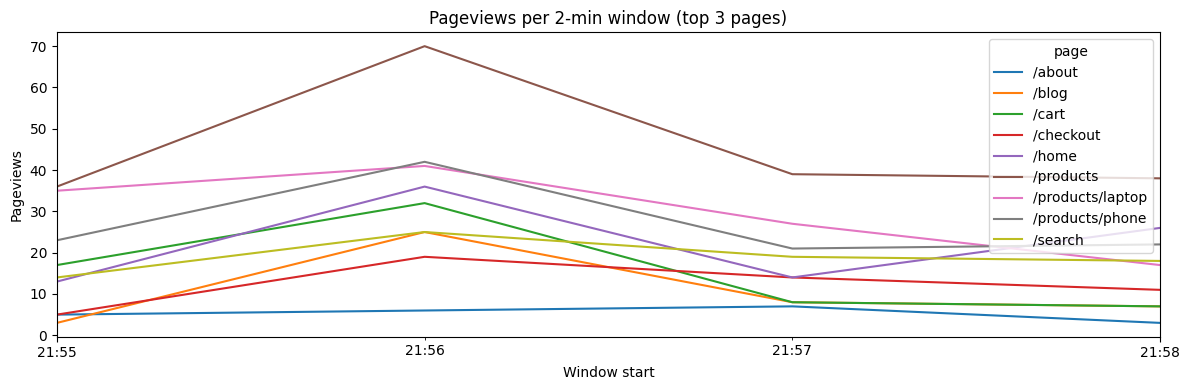

  Producer: 1150 events sent
  Producer: 1200 events sent
  Producer: 1250 events sent
  Producer: 1300 events sent


In [ ]:
import matplotlib.pyplot as plt, pandas as pd

# Pageviews over time for the top 3 pages
ts = con.execute("""
    WITH top3 AS (
        SELECT page FROM pg.public.clickstream_windows
        GROUP BY page
        ORDER BY SUM(pageviews) DESC
        LIMIT 10
    )
    SELECT w.window_start,
           w.page,
           MAX(w.pageviews) AS pageviews
    FROM pg.public.clickstream_windows w
    INNER JOIN top3 ON top3.page = w.page
    where w.window_start >= (SELECT MAX(window_start) - INTERVAL '20 minutes' FROM pg.public.clickstream_windows)
    GROUP BY w.window_start, w.page
    ORDER BY w.window_start, w.page
""").df()

if ts.empty:
    print('No data yet — wait a few seconds and re-run')
else:
    pivot = ts.pivot(index='window_start', columns='page', values='pageviews').fillna(0)
    pivot.plot(figsize=(12, 4), title='Pageviews per 2-min window (top 3 pages)')
    plt.xlabel('Window start')
    plt.ylabel('Pageviews')
    plt.tight_layout()
    plt.show()

---
## Step 6 · Simulate a traffic spike

Stop the current producer, start a new one that hammers `/checkout` — you should see the spike appear in the chart within the next window.

In [ ]:
# Stop the old producer
_stop_producer.set()
time.sleep(1)

# Spike: send 200 /checkout events quickly
spike_prod = KafkaProducer(
    bootstrap_servers=KAFKA_SERVERS,
    value_serializer=lambda v: json.dumps(v).encode(),
)
for _ in range(200):
    spike_prod.send('clickstream', value={
        'event_id': str(uuid.uuid4()),
        'user_id':  random.randint(1, N_USERS),
        'page':     '/checkout',
        'referrer': '/cart',
        'ts':       datetime.now(timezone.utc).isoformat(),
    })
spike_prod.flush()
print('Spike sent — re-run the chart cell after the next 15-second trigger')

---
## Step 7 · Monitor and stop

In [ ]:
# Check query health
print('Active?  ', query.isActive)
print('Progress:', query.lastProgress)

In [ ]:
# Stop everything cleanly
_stop_producer.set()
query.stop()
print('Stream and producer stopped.')

Stream and producer stopped.


Producer stopped. Total sent: 27842
  batch 328: 11 rows → postgres | 2 alerts → clickstream-alerts


26/07/01 23:29:15 WARN TaskSetManager: Lost task 0.0 in stage 5480.0 (TID 412726) (172.20.0.6 executor 0): org.apache.spark.sql.kafka010.KafkaIllegalStateException: Some data may have been lost because they are not available in Kafka any more;
either the data was aged out by Kafka or the topic may have been deleted before all the data in the
topic was processed.
If you don't want your streaming query to fail on such cases, set the source option failOnDataLoss to false.
Reason: Could not read records in offset [40473, 40477) for topic partition clickstream-0
with consumer group spark-kafka-source-9a9b6f81-ade6-471b-a02b-00734efa8867--47185669-executor.
	at org.apache.spark.sql.kafka010.KafkaExceptions$.couldNotReadOffsetRange(KafkaExceptions.scala:101)
	at org.apache.spark.sql.kafka010.consumer.KafkaDataConsumer.throwOnDataLoss(KafkaDataConsumer.scala:660)
	at org.apache.spark.sql.kafka010.consumer.KafkaDataConsumer.$anonfun$get$1(KafkaDataConsumer.scala:347)
	at org.apache.spark.util.U

---
## Challenge — try it yourself

1. **Tumbling vs sliding windows** — change `window('event_time', '2 minutes', '30 seconds')` to a tumbling window (`window('event_time', '1 minute')`). How does the chart change?

2. **Session windows** — Spark 3.2+ has `session_window(col, gap)`. Replace the time-based window with `session_window('event_time', '30 seconds')` to group events per user session. You'll need to add `user_id` to the `groupBy`.

3. **Upsert instead of append** — `foreachBatch` can run raw SQL. Use `psycopg2` inside `write_batch` to do:
   ```sql
   INSERT INTO clickstream_windows ... ON CONFLICT (window_start, page) DO UPDATE SET ...
   ```
   This keeps exactly one row per (window, page) and makes queries simpler.

4. **Dead-letter queue** — add a second Kafka producer call inside `write_batch` that sends failed rows (e.g. `pageviews > 1000`) to a `clickstream-alerts` topic. Consume that topic in a second `readStream`.

5. **Delta Lake sink** — replace the JDBC `foreachBatch` with a Delta Lake `writeStream` sink (`format('delta')`). Query the Delta table with DuckDB using `delta_scan()` (requires the `duckdb-delta` extension).

---
## Challenge Solutions

### Challenge 1 · Tumbling vs Sliding Windows

**Tumbling** — non-overlapping buckets. Each event belongs to exactly **one** window.  
`window('event_time', '1 minute')` → windows: [00:00–01:00), [01:00–02:00), …

**Sliding** — overlapping buckets. Each event can belong to **multiple** windows (one per slide step).  
`window('event_time', '2 minutes', '30 seconds')` → windows: [00:00–02:00), [00:30–02:30), …

**When to choose which:**
- Tumbling → billing, hourly reports — you want clean, non-overlapping periods
- Sliding → rolling metrics (last-N-minutes dashboards) — you want a smooth, continuously-updated view

To observe the difference: run the cell below with each config and compare the DuckDB chart cell — sliding produces ~4× more rows in `clickstream_windows` for the same data.

In [12]:
import shutil

# --- pick ONE window definition and re-run this cell + the sink cell ---

# TUMBLING: one row per (page, minute) — clean, no overlap
tumbling = (
    clicks
    .withWatermark('event_time', '15 seconds')
    .groupBy(F.window('event_time', '1 minute').alias('window'), 'page')
    .agg(
        F.count('*').alias('pageviews'),
        F.approx_count_distinct('user_id').alias('unique_users'),
    )
    .select(
        F.col('window.start').alias('window_start'),
        F.col('window.end').alias('window_end'),
        'page', 'pageviews', 'unique_users',
    )
)

# SLIDING: each event counted in multiple overlapping buckets
sliding = (
    clicks
    .withWatermark('event_time', '15 seconds')
    .groupBy(F.window('event_time', '2 minutes', '30 seconds').alias('window'), 'page')
    .agg(
        F.count('*').alias('pageviews'),
        F.approx_count_distinct('user_id').alias('unique_users'),
    )
    .select(
        F.col('window.start').alias('window_start'),
        F.col('window.end').alias('window_end'),
        'page', 'pageviews', 'unique_users',
    )
)

# Swap `tumbling` → `sliding` here to compare
active_windowed = tumbling

shutil.rmtree('/home/jupyter/data/checkpoints/ch1_windows', ignore_errors=True)
q_ch1 = (
    active_windowed.writeStream
    .outputMode('update')
    .foreachBatch(write_batch)          # reuses write_batch from Step 4
    .option('checkpointLocation', '/home/jupyter/data/checkpoints/ch1_windows')
    .trigger(processingTime='15 seconds')
    .start()
)
print(f'Challenge 1 query started — using {"TUMBLING" if active_windowed is tumbling else "SLIDING"} window')

Challenge 1 query started — using TUMBLING window


26/07/01 21:57:28 WARN ResolveWriteToStream: spark.sql.adaptive.enabled is not supported in streaming DataFrames/Datasets and will be disabled.


  Producer: 700 events sent
  batch 1: 4 rows → postgres
  Producer: 750 events sent
  batch 2: 9 rows → postgres
  Producer: 800 events sent
  Producer: 850 events sent
  batch 3: 9 rows → postgres


In [13]:
q_ch1.stop()

26/07/01 21:58:47 WARN DAGScheduler: Failed to cancel job group 55669711-bd70-49ff-8e55-47c2f2148aad. Cannot find active jobs for it.


26/07/01 21:58:47 WARN TaskSetManager: Lost task 90.0 in stage 106.0 (TID 7930) (172.20.0.6 executor 0): TaskKilled (Stage cancelled: [SPARK_JOB_CANCELLED] Job 39 cancelled Query [id = dceee79f-cc5b-4317-950c-c7bf09355d80, runId = 55669711-bd70-49ff-8e55-47c2f2148aad] was stopped SQLSTATE: XXKDA)
26/07/01 21:58:47 WARN TaskSetManager: Lost task 89.0 in stage 106.0 (TID 7929) (172.20.0.6 executor 0): TaskKilled (Stage cancelled: [SPARK_JOB_CANCELLED] Job 39 cancelled Query [id = dceee79f-cc5b-4317-950c-c7bf09355d80, runId = 55669711-bd70-49ff-8e55-47c2f2148aad] was stopped SQLSTATE: XXKDA)


  Producer: 1100 events sent


### Challenge 2 · Session Windows

A **session window** groups events by inactivity gap, not by clock time.  
`session_window('event_time', '30 seconds')` — a new session starts whenever there is a ≥30 s gap in a user's activity.

Key differences from time windows:
- Window length **varies** per user/group — a power user who clicks every 2 s gets a long session; a user who clicks once gets a 30-s window
- You **must** include the grouping key (here `user_id`) — otherwise all users' events merge into one session
- Output mode must be `update` (sessions grow until the gap expires and the watermark passes)

In [16]:
import shutil

sessions_df = (
    clicks
    .withWatermark('event_time', '30 seconds')
    .groupBy(
        F.session_window('event_time', '30 seconds').alias('session'),
        'user_id',
    )
    .agg(
        F.count('*').alias('page_clicks'),
        F.approx_count_distinct('page').alias('distinct_pages'),
    )
    .select(
        F.col('session.start').alias('session_start'),
        F.col('session.end').alias('session_end'),
        'user_id',
        'page_clicks',
        'distinct_pages',
        # session duration in seconds
        (F.unix_timestamp('session.end') - F.unix_timestamp('session.start')).alias('duration_secs'),
    )
)

def write_sessions(batch_df, batch_id):
    if batch_df.isEmpty():
        return
    n = batch_df.count()
    batch_df.write.jdbc(PG_URL, 'clickstream_sessions', mode='append', properties=PG_PROPS)
    print(f'  batch {batch_id}: {n} sessions → postgres')

shutil.rmtree('/home/jupyter/data/checkpoints/ch2_sessions', ignore_errors=True)
q_ch2 = (
    sessions_df.writeStream
    .outputMode('append')
    .foreachBatch(write_sessions)
    .option('checkpointLocation', '/home/jupyter/data/checkpoints/ch2_sessions')
    .trigger(processingTime='15 seconds')
    .start()
)
print('Challenge 2 session query started.')

Challenge 2 session query started.


26/07/01 21:59:50 WARN ResolveWriteToStream: spark.sql.adaptive.enabled is not supported in streaming DataFrames/Datasets and will be disabled.


  Producer: 1400 events sent
  Producer: 1450 events sent
  Producer: 1500 events sent
  Producer: 1550 events sent
  Producer: 1600 events sent
  Producer: 1650 events sent
  Producer: 1700 events sent


In [ ]:
q_ch2.stop()

26/07/01 22:01:03 WARN DAGScheduler: Failed to cancel job group 2b1a51af-6370-4883-aa32-1fa2a1ebc624. Cannot find active jobs for it.
26/07/01 22:01:03 WARN DAGScheduler: Failed to cancel job group 2b1a51af-6370-4883-aa32-1fa2a1ebc624. Cannot find active jobs for it.


  Producer: 1750 events sent
  Producer: 1800 events sent
  Producer: 1850 events sent
  Producer: 1900 events sent
  Producer: 1950 events sent
  Producer: 2000 events sent


### Challenge 3 · Upsert instead of append

The default `mode='append'` in Step 4 writes a **new row every trigger** for the same `(window_start, page)` — the table grows without bound and queries need `MAX()` or deduplication to get the latest count.

An upsert (`ON CONFLICT DO UPDATE`) keeps **exactly one row per (window_start, page)** and updates it in place every trigger. Queries are simpler and the table stays compact.

The pattern: in `foreachBatch`, open a `psycopg2` connection on the executor (the batch is a static DataFrame at this point) and run raw SQL for each row.

> **Note:** `psycopg2` runs on the Jupyter kernel process, not on the Spark executor. Because `foreachBatch` hands us a static DataFrame, `.collect()` pulls all rows back to the driver before the SQL loop — safe for small batches (window rows), but avoid this pattern for large raw-event tables.

In [18]:
import shutil
import psycopg2

def _pg_conn():
    return psycopg2.connect(
        dbname=os.getenv('POSTGRES_DB', 'sandbox'),
        host=os.getenv('POSTGRES_HOST', 'postgres'),
        user=os.getenv('POSTGRES_USER', 'spark'),
        password=os.getenv('POSTGRES_PASSWORD', 'spark123'),
    )

# Create table with a primary key so ON CONFLICT works
with _pg_conn() as conn, conn.cursor() as cur:
    cur.execute("""
        CREATE TABLE IF NOT EXISTS clickstream_windows_upsert (
            window_start  TIMESTAMPTZ NOT NULL,
            window_end    TIMESTAMPTZ NOT NULL,
            page          TEXT        NOT NULL,
            pageviews     BIGINT,
            unique_users  BIGINT,
            PRIMARY KEY (window_start, page)
        )
    """)
print('Table ready.')

def write_batch_upsert(batch_df, batch_id):
    if batch_df.isEmpty():
        return
    rows = batch_df.collect()           # pull to driver — fine for window aggregates
    with _pg_conn() as conn, conn.cursor() as cur:
        for row in rows:
            cur.execute("""
                INSERT INTO clickstream_windows_upsert
                    (window_start, window_end, page, pageviews, unique_users)
                VALUES (%s, %s, %s, %s, %s)
                ON CONFLICT (window_start, page)
                DO UPDATE SET
                    pageviews    = EXCLUDED.pageviews,
                    unique_users = EXCLUDED.unique_users,
                    window_end   = EXCLUDED.window_end
            """, (row.window_start, row.window_end, row.page, row.pageviews, row.unique_users))
    print(f'  batch {batch_id}: {len(rows)} rows upserted → clickstream_windows_upsert')

shutil.rmtree('/home/jupyter/data/checkpoints/ch3_upsert', ignore_errors=True)
q_ch3 = (
    windowed.writeStream
    .outputMode('update')
    .foreachBatch(write_batch_upsert)
    .option('checkpointLocation', '/home/jupyter/data/checkpoints/ch3_upsert')
    .trigger(processingTime='15 seconds')
    .start()
)
print('Challenge 3 upsert query started.')

Table ready.
Challenge 3 upsert query started.


26/07/01 22:02:00 WARN ResolveWriteToStream: spark.sql.adaptive.enabled is not supported in streaming DataFrames/Datasets and will be disabled.


  Producer: 2050 events sent
  Producer: 2100 events sent
  batch 1: 9 rows upserted → clickstream_windows_upsert
  Producer: 2150 events sent
  batch 2: 9 rows upserted → clickstream_windows_upsert
  Producer: 2200 events sent
  batch 3: 9 rows upserted → clickstream_windows_upsert
  Producer: 2250 events sent
  Producer: 2300 events sent
  batch 4: 9 rows upserted → clickstream_windows_upsert
  Producer: 2350 events sent
  batch 5: 9 rows upserted → clickstream_windows_upsert
  Producer: 2400 events sent
  Producer: 2450 events sent
  batch 6: 9 rows upserted → clickstream_windows_upsert
  Producer: 2500 events sent
  batch 7: 9 rows upserted → clickstream_windows_upsert
  Producer: 2550 events sent
  Producer: 2600 events sent
  batch 8: 9 rows upserted → clickstream_windows_upsert
  Producer: 2650 events sent
  batch 9: 9 rows upserted → clickstream_windows_upsert
  Producer: 2700 events sent
  Producer: 2750 events sent
  batch 10: 8 rows upserted → clickstream_windows_upsert
  Pr

In [19]:
q_ch3.stop()

26/07/01 22:07:03 WARN TaskSetManager: Lost task 101.0 in stage 228.0 (TID 17284) (172.20.0.6 executor 0): TaskKilled (Stage cancelled: [SPARK_JOB_CANCELLED] Job 86 cancelled Query [id = 9d1d124c-bdb9-4bc6-ae3f-4c7788c7c56a, runId = 9ce2b1a7-bf7e-4d77-a067-e6488ff91258] was stopped SQLSTATE: XXKDA)
26/07/01 22:07:03 WARN DAGScheduler: Failed to cancel job group 9ce2b1a7-bf7e-4d77-a067-e6488ff91258. Cannot find active jobs for it.


26/07/01 22:07:03 WARN TaskSetManager: Lost task 100.0 in stage 228.0 (TID 17283) (172.20.0.6 executor 0): TaskKilled (Stage cancelled: [SPARK_JOB_CANCELLED] Job 86 cancelled Query [id = 9d1d124c-bdb9-4bc6-ae3f-4c7788c7c56a, runId = 9ce2b1a7-bf7e-4d77-a067-e6488ff91258] was stopped SQLSTATE: XXKDA)


### Challenge 4 · Dead-Letter Queue

A **dead-letter queue (DLQ)** is a second Kafka topic that receives rows that fail validation or exceed a threshold — instead of silently dropping them or crashing the pipeline.

Architecture:
```
windowed stream
   └── foreachBatch
         ├── normal rows (pageviews ≤ threshold) → PostgreSQL
         └── hot rows  (pageviews > threshold)  → clickstream-alerts topic
                                                       ↓
                                             second readStream
                                                  (console sink for demo)
```

The alert consumer can later fan out to PagerDuty, Slack, or an anomaly table — the DLQ decouples detection from response.

In [20]:
import shutil, json

ALERT_THRESHOLD = 50   # pageviews per window that triggers an alert

alert_prod = KafkaProducer(
    bootstrap_servers=KAFKA_SERVERS,
    value_serializer=lambda v: json.dumps(v).encode(),
)

def write_batch_dlq(batch_df, batch_id):
    if batch_df.isEmpty():
        return

    normal_df = batch_df.filter(F.col('pageviews') <= ALERT_THRESHOLD)
    hot_df    = batch_df.filter(F.col('pageviews') >  ALERT_THRESHOLD)

    if not normal_df.isEmpty():
        normal_df.write.jdbc(PG_URL, 'clickstream_windows', mode='append', properties=PG_PROPS)

    hot_rows = hot_df.collect()
    for row in hot_rows:
        alert_prod.send('clickstream-alerts', value={
            'window_start': str(row.window_start),
            'window_end':   str(row.window_end),
            'page':         row.page,
            'pageviews':    int(row.pageviews),
            'unique_users': int(row.unique_users),
            'alert_type':   'high_traffic',
        })
    if hot_rows:
        alert_prod.flush()

    n_normal = normal_df.count() if not normal_df.isEmpty() else 0
    print(f'  batch {batch_id}: {n_normal} rows → postgres | {len(hot_rows)} alerts → clickstream-alerts')


# ── Alert consumer: second readStream ──────────────────────────────────────
alert_schema = StructType([
    StructField('window_start', StringType()),
    StructField('window_end',   StringType()),
    StructField('page',         StringType()),
    StructField('pageviews',    LongType()),
    StructField('unique_users', LongType()),
    StructField('alert_type',   StringType()),
])

alerts_stream = (
    spark.readStream
    .format('kafka')
    .option('kafka.bootstrap.servers', KAFKA_SERVERS)
    .option('subscribe', 'clickstream-alerts')
    .option('startingOffsets', 'latest')
    .load()
    .select(F.from_json(F.col('value').cast('string'), alert_schema).alias('a'))
    .select('a.*')
)

shutil.rmtree('/home/jupyter/data/checkpoints/ch4_alerts_consumer', ignore_errors=True)
q_ch4_consumer = (
    alerts_stream.writeStream
    .outputMode('append')
    .format('console')
    .option('truncate', False)
    .option('checkpointLocation', '/home/jupyter/data/checkpoints/ch4_alerts_consumer')
    .trigger(processingTime='15 seconds')
    .start()
)

shutil.rmtree('/home/jupyter/data/checkpoints/ch4_dlq', ignore_errors=True)
q_ch4 = (
    windowed.writeStream
    .outputMode('update')
    .foreachBatch(write_batch_dlq)
    .option('checkpointLocation', '/home/jupyter/data/checkpoints/ch4_dlq')
    .trigger(processingTime='15 seconds')
    .start()
)
print(f'Challenge 4 DLQ pipeline started. Alert threshold: pageviews > {ALERT_THRESHOLD}')

Challenge 4 DLQ pipeline started. Alert threshold: pageviews > 50


26/07/01 22:07:07 WARN ResolveWriteToStream: spark.sql.adaptive.enabled is not supported in streaming DataFrames/Datasets and will be disabled.
26/07/01 22:07:07 WARN ResolveWriteToStream: spark.sql.adaptive.enabled is not supported in streaming DataFrames/Datasets and will be disabled.
26/07/01 22:07:07 WARN KafkaOffsetReaderAdmin: Error in attempt 1 getting Kafka offsets: 
java.util.concurrent.ExecutionException: org.apache.kafka.common.errors.UnknownTopicOrPartitionException: This server does not host this topic-partition.
	at java.base/java.util.concurrent.CompletableFuture.reportGet(CompletableFuture.java:396)
	at java.base/java.util.concurrent.CompletableFuture.get(CompletableFuture.java:2073)
	at org.apache.kafka.common.internals.KafkaFutureImpl.get(KafkaFutureImpl.java:165)
	at org.apache.spark.sql.kafka010.ConsumerStrategy.retrieveAllPartitions(ConsumerStrategy.scala:65)
	at org.apache.spark.sql.kafka010.ConsumerStrategy.retrieveAllPartitions$(ConsumerStrategy.scala:64)
	at or

26/07/01 22:07:08 WARN KafkaOffsetReaderAdmin: Error in attempt 2 getting Kafka offsets: 
java.util.concurrent.ExecutionException: org.apache.kafka.common.errors.UnknownTopicOrPartitionException: This server does not host this topic-partition.
	at java.base/java.util.concurrent.CompletableFuture.reportGet(CompletableFuture.java:396)
	at java.base/java.util.concurrent.CompletableFuture.get(CompletableFuture.java:2073)
	at org.apache.kafka.common.internals.KafkaFutureImpl.get(KafkaFutureImpl.java:165)
	at org.apache.spark.sql.kafka010.ConsumerStrategy.retrieveAllPartitions(ConsumerStrategy.scala:65)
	at org.apache.spark.sql.kafka010.ConsumerStrategy.retrieveAllPartitions$(ConsumerStrategy.scala:64)
	at org.apache.spark.sql.kafka010.SubscribeStrategy.retrieveAllPartitions(ConsumerStrategy.scala:101)
	at org.apache.spark.sql.kafka010.SubscribeStrategy.assignedTopicPartitions(ConsumerStrategy.scala:112)
	at org.apache.spark.sql.kafka010.KafkaOffsetReaderAdmin.$anonfun$partitionsAssignedToAd

  Producer: 3550 events sent
  Producer: 3600 events sent
  batch 1: 9 rows → postgres | 0 alerts → clickstream-alerts
  Producer: 3650 events sent
  batch 2: 9 rows → postgres | 0 alerts → clickstream-alerts
  Producer: 3700 events sent
  Producer: 3750 events sent
  batch 3: 8 rows → postgres | 1 alerts → clickstream-alerts
  Producer: 3800 events sent
  batch 4: 8 rows → postgres | 1 alerts → clickstream-alerts
  Producer: 3850 events sent
  Producer: 3900 events sent
  batch 5: 9 rows → postgres | 0 alerts → clickstream-alerts
  Producer: 3950 events sent
  batch 6: 9 rows → postgres | 0 alerts → clickstream-alerts
  Producer: 4000 events sent
  Producer: 4050 events sent
  batch 7: 9 rows → postgres | 0 alerts → clickstream-alerts
  Producer: 4100 events sent
  batch 8: 7 rows → postgres | 2 alerts → clickstream-alerts
  Producer: 4150 events sent
  Producer: 4200 events sent
  batch 9: 8 rows → postgres | 0 alerts → clickstream-alerts
  Producer: 4250 events sent
  batch 10: 9 ro

### Challenge 5 · Delta Lake Sink

Delta Lake adds **ACID transactions**, **schema enforcement**, and **time-travel** on top of Parquet files — great for streaming sinks because it handles concurrent writes and partial-batch failures safely.

**What changes from the JDBC approach:**
| | JDBC / PostgreSQL | Delta Lake |
|---|---|---|
| Sink format | `foreachBatch` + JDBC write | native `format('delta')` |
| Update mode | append duplicates; upsert via psycopg2 | `update` mode supported natively |
| Query tool | DuckDB `ATTACH ... POSTGRES` | DuckDB `delta_scan()` |
| Schema evolution | manual `ALTER TABLE` | `mergeSchema` option |

**Prerequisites** — the SparkSession must be created with these configs (restart kernel and add to `setup` cell if not already present):
```python
.config('spark.jars.packages', 'io.delta:delta-spark_2.13:4.0.0')
.config('spark.sql.extensions', 'io.delta.sql.DeltaSparkSessionExtension')
.config('spark.sql.catalog.spark_catalog', 'org.apache.spark.sql.delta.catalog.DeltaCatalog')
```
DuckDB also needs the delta extension: `con.execute("INSTALL delta; LOAD delta")`

In [21]:
import shutil

DELTA_PATH = '/home/jupyter/data/delta/clickstream_windows'

shutil.rmtree('/home/jupyter/data/checkpoints/ch5_delta', ignore_errors=True)

q_ch5 = (
    windowed.writeStream
    .outputMode(' vb')        # Delta supports update mode natively — no foreachBatch needed
    .format('delta')
    .option('checkpointLocation', '/home/jupyter/data/checkpoints/ch5_delta')
    .option('path', DELTA_PATH)
    .trigger(processingTime='15 seconds')
    .start()
)
print(f'Challenge 5: Delta Lake sink writing to {DELTA_PATH}')

# ── Query with DuckDB ──────────────────────────────────────────────────────
# Run this block after a few triggers have fired

# con.execute("INSTALL delta; LOAD delta")   # run once per session

# delta_df = con.execute(f"""
#     SELECT page,
#            SUM(pageviews)    AS total_pageviews,
#            MAX(window_end)   AS latest_window
#     FROM delta_scan('{DELTA_PATH}')
#     GROUP BY page
#     ORDER BY total_pageviews DESC
# """).df()
# delta_df

# ── Time-travel: read a snapshot from N versions ago ──────────────────────
# delta_df_v0 = con.execute(f"""
#     SELECT * FROM delta_scan('{DELTA_PATH}', version => 0) LIMIT 10
# """).df()
# delta_df_v0

AnalysisException: [DELTA_UNSUPPORTED_OUTPUT_MODE] Data source org.apache.spark.sql.delta.sources.DeltaDataSource does not support Update output mode

  Producer: 4500 events sent
  batch 13: 9 rows → postgres | 0 alerts → clickstream-alerts
  Producer: 4550 events sent
  batch 14: 9 rows → postgres | 0 alerts → clickstream-alerts
  Producer: 4600 events sent
  Producer: 4650 events sent
  batch 15: 8 rows → postgres | 1 alerts → clickstream-alerts
  Producer: 4700 events sent
  batch 16: 8 rows → postgres | 1 alerts → clickstream-alerts
  Producer: 4750 events sent
  Producer: 4800 events sent
  batch 17: 9 rows → postgres | 0 alerts → clickstream-alerts
  Producer: 4850 events sent
  batch 18: 9 rows → postgres | 0 alerts → clickstream-alerts
  Producer: 4900 events sent
  Producer: 4950 events sent
  batch 19: 9 rows → postgres | 0 alerts → clickstream-alerts
  Producer: 5000 events sent
  batch 20: 7 rows → postgres | 2 alerts → clickstream-alerts
  Producer: 5050 events sent
  Producer: 5100 events sent
  batch 21: 9 rows → postgres | 0 alerts → clickstream-alerts
  Producer: 5150 events sent
  batch 22: 9 rows → postgres | 0 al

26/07/01 23:28:48 WARN ProcessingTimeExecutor: Current batch is falling behind. The trigger interval is 15000} milliseconds, but spent 18551 milliseconds


  Producer: 27800 events sent
  batch 327: 9 rows → postgres | 0 alerts → clickstream-alerts
